# GRACE-FS Melt-Quench Tutorial: Na2O-SiO2 Glass

This notebook demonstrates using the **GRACE-FS** universal machine-learned interatomic potential (MLIP) to melt-quench a Na2O-SiO2 glass with amorphouspy, via LAMMPS's native `pair_style grace/fs`.

[GRACE](https://gracemaker.readthedocs.io/) is a universal foundation model, which is unlike the classical potentials in amorphouspy (PMMCS, SHIK, BJP, BMP, Du/Teter, Yang2026), it needs no per-element charge or pair parameterization. amorphouspy wraps an already-exported GRACE-FS checkpoint (a native, TensorFlow-free YAML file) as a potential via `generate_potential(..., potential_type="grace")`, exactly like any other potential.

**Scope note:** only single-layer/local ("FS") GRACE checkpoints are supported, which are the ones exportable to this native YAML format and runnable with `pair_style grace/fs`. Two-layer/three-layer "semilocal" checkpoints need a TensorFlow- or KOKKOS-linked LAMMPS build that amorphouspy does not provide. See `amorphouspy.lammps.potentials.grace_potential` for the full rationale.

Sections:
1. Prerequisite: exporting a GRACE-FS checkpoint (one-time, external step)
2. Structure generation
3. Potential generation
4. Potential selection — GRACE is opt-in
5. Melt-quench simulation *(requires a real checkpoint — skipped during automated notebook testing)*
6. Post-processing
7. Custom schedule with `md_simulation` *(skipped during automated notebook testing)*

## 1. Prerequisite: Exporting a GRACE-FS Checkpoint

`generate_grace_potential()` never downloads or exports models itself (no network access, no subprocess calls) — it only resolves and validates the path to an *already-exported* `FS_model.yaml`.

**Important:** the `grace-tensorpotential` package (which provides the `grace_models`/`grace_utils` CLI tools used below) depends on TensorFlow, whose conda-forge builds only support Python ≤3.12 — incompatible with amorphouspy's own pixi environment (pinned to Python 3.13 for the `lammps==2025.07.22` build that provides `pair_style grace/fs`). Run this **one-time export step in a separate environment**:

```bash
conda create -n grace-export -c conda-forge python=3.12 grace-tensorpotential
conda activate grace-export

model_name=GRACE-FS-OAM
checkpoint_dir=~/.cache/grace/checkpoints/$model_name
grace_models checkpoint $model_name
grace_utils -p $checkpoint_dir/model.yaml -c $checkpoint_dir/checkpoint export -sf -n $checkpoint_dir/FS_model.yaml
```

The resulting `FS_model.yaml` lives at `~/.cache/grace/checkpoints/GRACE-FS-OAM/FS_model.yaml` by default — the same path `generate_potential(..., potential_type="grace")` looks for in *this* environment. It's readable here (it's just a file) even though it can only be *produced* by the separate Python ≤3.12 environment above.

If `grace_models checkpoint GRACE-FS-OAM` isn't recognised, run `grace_models list` to see the checkpoints available for your installed `grace-tensorpotential` version (exact names drift across releases). Pass `model_path=` to `generate_potential`/`generate_grace_potential` to point at a checkpoint exported elsewhere instead of the default cache location.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

import amorphouspy as am
from amorphouspy.lammps.potentials.grace_potential import DEFAULT_MODEL_NAME
from amorphouspy.lammps.potentials.potential import (
    compatible_potentials,
    generate_potential,
    get_supported_elements,
    select_potential,
)

## 2. Structure Generation

A small Na2O-SiO2 (sodium silicate) structure, built here through amorphouspy's composition-driven workflow.

In [2]:
composition = {"SiO2": 0.70, "Na2O": 0.30}
struct_dict = am.get_structure_dict(composition, n_molecules=100, random_seed=4200)
atoms = am.get_ase_structure(struct_dict)
print(atoms)
print("Box:", struct_dict["box"], "A")

Atoms(symbols='Na60O170Si70', pbc=True, cell=[15.974467054614914, 15.974467054614914, 15.974467054614914], id=..., initial_charges=..., masses=..., mmcharges=..., type=...)
Box: 15.974467054614914 A


## 3. Potential Generation

`generate_potential(atoms_dict, potential_type="grace")` resolves the checkpoint (default: `~/.cache/grace/checkpoints/GRACE-FS-OAM/FS_model.yaml`) and returns the same `Name`/`Filename`/`Model`/`Species`/`Config` DataFrame every other potential returns — no charges, no electrostatics, `atom_style atomic`.

This cell runs whether or not a checkpoint has been exported yet: if it's missing, `generate_potential` raises `FileNotFoundError` with the exact remediation commands from Section 1, which we catch and print below instead of letting the notebook fail.

In [3]:
default_model_path = Path("~/.cache/grace/checkpoints").expanduser() / DEFAULT_MODEL_NAME / "FS_model.yaml"
print("Default GRACE-FS-OAM model path:", default_model_path)
print("Exported already?", default_model_path.exists())

try:
    potential_grace = generate_potential(struct_dict, potential_type="grace")
    print("\n--- GRACE config lines ---")
    for line in potential_grace.loc[0, "Config"]:
        print(line, end="")
except FileNotFoundError as e:
    potential_grace = None
    print("\nNo exported checkpoint found yet — this is the exact guidance generate_potential() raises:\n")
    print(e)

Default GRACE-FS-OAM model path: /Users/achrafatila/.cache/grace/checkpoints/GRACE-FS-OAM/FS_model.yaml
Exported already? True

--- GRACE config lines ---
# GRACE-FS universal machine-learned potential (grace-tensorpotential)
# https://gracemaker.readthedocs.io/

units metal
dimension 3
atom_style atomic

### Group Definitions ###
group Na type 1
group O type 2
group Si type 3

### GRACE-FS Potential ###
pair_style grace/fs
pair_coeff * * "/Users/achrafatila/.cache/grace/checkpoints/GRACE-FS-OAM/FS_model.yaml" Na O Si

thermo_style custom step temp pe etotal pxx pxy pxz pyy pyz pzz vol
thermo_modify flush no
thermo 100


## 4. Potential Selection — GRACE Is Opt-In

`select_potential()` only auto-selects classical, parameter-fitted potentials (PMMCS, SHIK, BJP, BMP, Du/Teter, Yang2026). GRACE is never auto-selected, because it needs a manually exported model and is far more expensive; use it by passing `potential_type="grace"` explicitly. `compatible_potentials()` still lists it, so it shows up as an option for compositions no classical potential covers. GRACE supports the elements the OMat24/Alexandria/MPtrj training data covers: Z=1–83 (H–Bi) plus Z=89–94 (Ac–Pu) — 89 elements total, everything except Po/At/Rn/Fr/Ra and anything heavier than Pu.

In [4]:
grace_elements = get_supported_elements("grace")
print(f"GRACE supports {len(grace_elements)} elements.")

examples = {
    "SiO2 (silica)": {"Si", "O"},
    "Na2O-CaO-SiO2 (soda-lime)": {"Na", "Ca", "Si", "O"},
    "Xe-Kr (noble gases, no classical potential)": {"Xe", "Kr"},
}
print(f"\n{'Composition':<45} {'Best':>9}  All compatible")
print("-" * 75)
for label, elements in examples.items():
    best = select_potential(elements)
    all_compat = compatible_potentials(elements)
    print(f"{label:<45} {best!s:>9}  {all_compat}")

GRACE supports 89 elements.

Composition                                        Best  All compatible
---------------------------------------------------------------------------
SiO2 (silica)                                     pmmcs  ['pmmcs', 'bmp-harmonic', 'bmp-screened-harmonic', 'shik', 'bjp', 'du_teter', 'du_teter_dbx_generalized', 'yang2026', 'grace']
Na2O-CaO-SiO2 (soda-lime)                         pmmcs  ['pmmcs', 'bmp-harmonic', 'bmp-screened-harmonic', 'shik', 'du_teter', 'du_teter_dbx_generalized', 'yang2026', 'grace']
Xe-Kr (noble gases, no classical potential)        None  ['grace']


## 5. Melt-Quench Simulation

> **Requires a real, exported GRACE-FS checkpoint** (Section 1) **and a LAMMPS build with `pair_style grace/fs`** (this repo's pinned conda-forge `lammps==2025.07.22` has it). The cell below is **skipped during automated notebook testing** (tagged `NBVAL_SKIP`, since no checkpoint is available in CI) — run it locally once you've completed the Prerequisites step.

GRACE has its own melt-quench protocol. After the optional stage 0 pre-equilibration of the random structure, it runs (all NPT stages at 0 GPa):

| Stage | Ensemble | Temperature | Default duration |
|---|---|---|---|
| 1 | NVT | T_high = 3500 K | 10 ps (fixed) |
| 2 | NPT | T_high | 50 ps |
| 3 | NPT | T_high → T_low = 300 K | 10 K/ps (320 ps) |
| 4 | NPT | T_low | 100 ps |
| 5 | NVT | T_low | 10 ps (fixed) |

`cooling_rate` (K/s) sets the length of stage 3, and `equilibration_steps` overrides the two NPT holds (stages 2 and 4) together. For independent control of each stage, chain `md_simulation` calls instead (Section 7). The cell below shortens the run for a quick demo; remove the two marked lines for production defaults.

In [5]:
potential_grace = generate_potential(struct_dict, potential_type="grace")

result = am.melt_quench_simulation(
    structure=atoms,
    potential=potential_grace,
    temperature_low=300.0,
    timestep=1.0,
    cooling_rate=1e15,  # demo only (1000 K/ps); for production: remove this line (default 10 K/ps)
    n_dump=None,
    n_print_thermo=1000,
    pre_equilibrate=True,
    thermostat="nose_hoover",
    equilibration_steps=1000,  # demo only; for production: remove this line (defaults 50 ps / 100 ps)
    seed=42,
    server_kwargs={"cores": 4},
)

glass = result["structure"]
history = result["result"]
print("Final structure:", glass)
print(f"Protocol stages: {len(history)}")

Final structure: Atoms(symbols='Na60O170Si70', pbc=True, cell=[[16.48016959173555, 3.027358040988672e-15, 3.027358040988672e-15], [-3.0273580409886718e-15, 16.48016959173555, 3.027358040988672e-15], [-3.0273580409886714e-15, -3.0273580409886718e-15, 16.48016959173555]], id=..., indices=..., initial_charges=..., masses=..., mmcharges=..., momenta=..., type=...)
Protocol stages: 6


## 6. Post-processing

> Also requires the melt-quench result from Section 5 — skipped during automated notebook testing.

Density from the final box volume, and the partial Si-O RDF, exactly as in `MeltquenchTutorial.ipynb`.

GRACE-quenched 30Na2O-70SiO2 glass density: 2.250 g/cm³  (experimental sodium silicate glass: ~2.47 g/cm³)


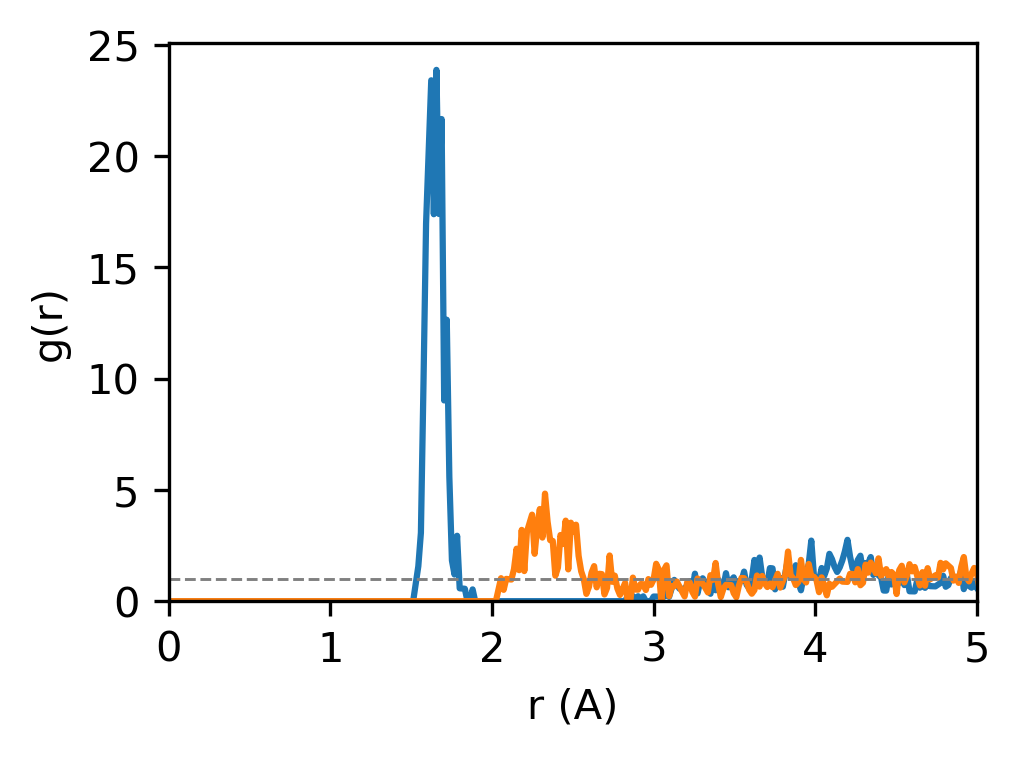

In [6]:
from ase.data import atomic_masses


def compute_density(structure):
    """Density in g/cm³ from an ASE Atoms object."""
    mass_amu = sum(atomic_masses[n] for n in structure.get_atomic_numbers())
    volume_A3 = structure.get_volume()
    return (mass_amu * 1.66054e-24) / (volume_A3 * 1e-24)


rho = compute_density(glass)
print(
    f"GRACE-quenched 30Na2O-70SiO2 glass density: {rho:.3f} g/cm\u00b3  (experimental sodium silicate glass: ~2.47 g/cm\u00b3)"
)

r, rdfs, cumcn = am.compute_rdf(
    structure=glass,
    r_max=8.0,
    n_bins=500,
    type_pairs=[(14, 8), (11, 8)],  # Si-O, Na-O
)

fig, ax = plt.subplots(figsize=(3.5, 3.5 / 1.3333), dpi=300)
for g in rdfs.values():
    ax.plot(r, g)
ax.axhline(1, ls="--", color="gray", lw=0.7)
ax.set_xlabel("r (A)")
ax.set_ylabel("g(r)")
ax.set_xlim(0, 5)
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

## 7. Custom Schedule with `md_simulation`

> Requires a real checkpoint — skipped during automated notebook testing.

For full control over every stage (for example, a longer NPT melt hold or a longer NVT anneal), chain `md_simulation` calls yourself, as in `MDTutorial.ipynb`. The schedule below reproduces the GRACE protocol; edit the durations in `schedule`. Stage 0 uses the same Langevin + nve/limit fix override as the protocol's pre-equilibration. Unlike the protocol, `md_simulation` re-creates velocities at `temperature_sim` at the start of every stage.

In [8]:
from amorphouspy.fabrication.pre_equilibration import pre_equilibration_fix_override

T_HIGH, T_LOW = 3500.0, 300.0  # K
COOLING_RATE = 1000.0  # K/ps
TIMESTEP = 1.0  # fs
SERVER_KWARGS = {"cores": 8}


def ps_to_steps(t_ps):
    return int(t_ps * 1000 / TIMESTEP)


# (label, ensemble, T_start, T_end, n_steps) -- edit the durations here
schedule = [
    ("NVT melt", "nvt", T_HIGH, None, ps_to_steps(1)),
    ("NPT melt", "npt", T_HIGH, None, ps_to_steps(5)),
    ("NPT cool", "npt", T_HIGH, T_LOW, ps_to_steps((T_HIGH - T_LOW) / COOLING_RATE)),
    ("NPT anneal", "npt", T_LOW, None, ps_to_steps(1)),
    ("NVT anneal", "nvt", T_LOW, None, ps_to_steps(1)),
]

# Stage 0: relax the randomly placed structure at T_HIGH
current = am.md_simulation(
    structure=atoms,
    potential=potential_grace,
    ensemble="nvt",
    temperature_sim=T_HIGH,
    timestep=TIMESTEP,
    production_steps=1_000,
    n_dump=None,
    n_print_thermo=1000,
    input_control_file={"fix": pre_equilibration_fix_override(T_HIGH)},
    server_kwargs=SERVER_KWARGS,
)["structure"]

custom_history = []
for label, ensemble, t_start, t_end, n_steps in schedule:
    res = am.md_simulation(
        structure=current,
        potential=potential_grace,
        ensemble=ensemble,
        temperature_sim=t_start,
        temperature_end=t_end,
        npt_pressure=0.0 if ensemble == "npt" else None,
        timestep=TIMESTEP,
        production_steps=n_steps,
        n_dump=None,
        n_print_thermo=1000,
        seed=42,
        server_kwargs=SERVER_KWARGS,
    )
    current = res["structure"]
    custom_history.append(res["result"])
    print(f"{label}: {n_steps} steps done")

custom_glass = current
print("Custom-schedule density:", f"{compute_density(custom_glass):.3f} g/cm\u00b3")

NVT melt: 1000 steps done
NPT melt: 5000 steps done
NPT cool: 3200 steps done
NPT anneal: 1000 steps done
NVT anneal: 1000 steps done
Custom-schedule density: 2.135 g/cm³
